<a href="https://colab.research.google.com/github/IMMAN99/ml-nids/blob/main/notebooks/01_eda.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
!pip install -q "pyspark==4.0.*" xgboost huggingface_hub
from google.colab import drive
drive.mount('/content/drive')
BASE = "/content/drive/MyDrive/Big Data/Project/ML-NIDS"
!mkdir -p /content/data
!cp --update=none "{BASE}/dataset/"chunk_*.parquet /content/data/

from pyspark.sql import SparkSession, functions as F
spark = (SparkSession.builder.appName("ML-NIDS").master("local[*]")
         .config("spark.driver.memory", "10g")
         .config("spark.sql.shuffle.partitions", "32").getOrCreate())
df = spark.read.parquet("/content/data/*.parquet")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:
!ls /content/data | wc -l
!du -sh /content/data

12
14G	/content/data


In [6]:
import os, shutil
src = f"{BASE}/dataset"
os.makedirs("/content/data", exist_ok=True)

def ok(s, d):
    if not os.path.exists(d) or os.path.getsize(d) != os.path.getsize(s):
        return False
    with open(d, "rb") as fh:
        fh.seek(-4, 2)
        return fh.read() == b"PAR1"

for f in sorted(os.listdir(src)):
    if not f.endswith(".parquet"):
        continue
    s, d = f"{src}/{f}", f"/content/data/{f}"
    if not ok(s, d):
        print("copying", f)
        shutil.copy(s, d)
    print(f, "OK" if ok(s, d) else "STILL BROKEN")

chunk_01.parquet OK
chunk_02.parquet OK
chunk_03.parquet OK
chunk_04.parquet OK
copying chunk_05.parquet
chunk_05.parquet OK
chunk_06.parquet OK
chunk_07.parquet OK
chunk_08.parquet OK
chunk_09.parquet OK
chunk_10.parquet OK
chunk_11.parquet OK
chunk_12.parquet OK


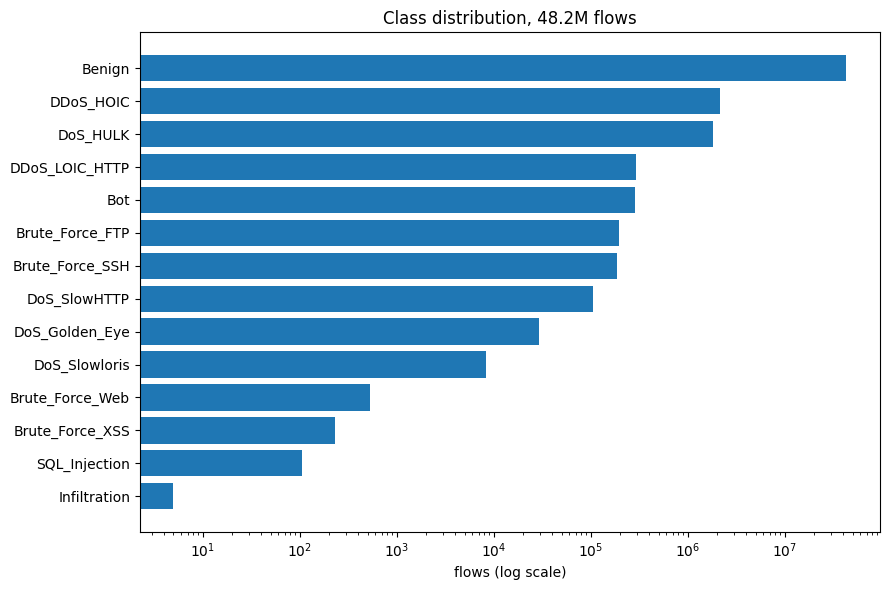

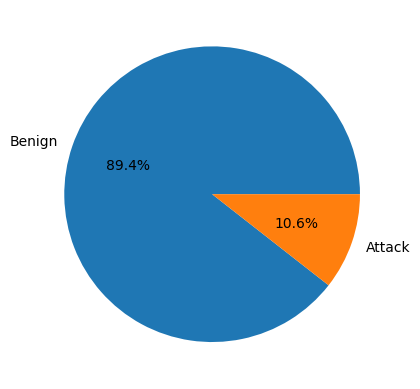

In [8]:
import pandas as pd, matplotlib.pyplot as plt
lc = pd.read_csv(f"{BASE}/reports/label_counts.csv").sort_values("count")

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(lc["label"], lc["count"])
ax.set_xscale("log"); ax.set_xlabel("flows (log scale)")
ax.set_title("Class distribution, 48.2M flows")
plt.tight_layout(); plt.savefig(f"{BASE}/reports/class_distribution.png", dpi=150); plt.show()

benign = lc.loc[lc.label == "Benign", "count"].sum()
attack = lc["count"].sum() - benign
plt.pie([benign, attack], labels=["Benign", "Attack"], autopct="%.1f%%")
plt.savefig(f"{BASE}/reports/benign_vs_attack.png", dpi=150); plt.show()

In [7]:
types = dict(df.dtypes)
skip = {"flow_id", "timestamp", "src_ip", "dst_ip", "protocol", "label"}
str_cols = [c for c, t in types.items() if t == "string" and c not in skip]
dbl_cols = [c for c, t in types.items() if t == "double"]
int_cols = [c for c, t in types.items() if t == "bigint"]

exprs = []
for c in str_cols:   # text that is not a number
    exprs.append(F.sum((F.col(c).isNotNull() &
        F.expr(f"try_cast(`{c}` as double)").isNull()).cast("int")).alias(f"{c}|non_numeric"))
for c in dbl_cols:
    exprs.append(F.sum(F.isnan(c).cast("int")).alias(f"{c}|nan"))
    exprs.append(F.sum(F.col(c).isin(float("inf"), float("-inf")).cast("int")).alias(f"{c}|inf"))
for c in str_cols + dbl_cols + int_cols:
    exprs.append(F.sum(F.col(c).isNull().cast("int")).alias(f"{c}|null"))

q = df.select(exprs).toPandas().T.reset_index()
q.columns = ["key", "count"]
q[["column", "problem"]] = q["key"].str.split("|", expand=True)
q = q[q["count"] > 0].drop(columns="key").sort_values("count", ascending=False)
q.to_csv(f"{BASE}/reports/quality_report.csv", index=False)
q

,count,column,problem
503,22954680,cov_fwd_payload_bytes_delta_len,inf
505,16484168,payload_bytes_cov,null
11,15109090,delta_start,non_numeric
12,15109090,handshake_duration,non_numeric
485,14213261,cov_bwd_payload_bytes_delta_len,inf
514,13836664,bwd_packets_IAT_skewness,null
504,13137827,payload_bytes_skewness,null
513,12965961,fwd_packets_IAT_skewness,null
512,11556459,packets_IAT_skewness,null
541,11155930,skewness_header_bytes,null


In [9]:
hs = (df.groupBy("label")
        .agg(F.count("*").alias("total"),
             F.sum((F.col("handshake_duration") == "not a complete handshake").cast("int")).alias("incomplete"))
        .withColumn("pct", F.round(100 * F.col("incomplete") / F.col("total"), 2))
        .orderBy(F.desc("pct")))
hs.show(truncate=False)
hs.toPandas().to_csv(f"{BASE}/reports/handshake_by_label.csv", index=False)

+---------------+--------+----------+-----+
|label          |total   |incomplete|pct  |
+---------------+--------+----------+-----+
|Brute_Force_FTP|193360  |193360    |100.0|
|DoS_SlowHTTP   |105550  |105550    |100.0|
|Bot            |286099  |143174    |50.04|
|Brute_Force_SSH|188444  |94237     |50.01|
|DDoS_HOIC      |2164586 |1082293   |50.0 |
|SQL_Injection  |106     |53        |50.0 |
|Brute_Force_Web|536     |268       |50.0 |
|Brute_Force_XSS|232     |115       |49.57|
|DoS_Slowloris  |8269    |3254      |39.35|
|Benign         |36425379|13462672  |36.96|
|DoS_Golden_Eye |29485   |2625      |8.9  |
|DoS_HULK       |1824450 |21290     |1.17 |
|DDoS_LOIC_HTTP |289527  |199       |0.07 |
+---------------+--------+----------+-----+



+---------------+-------------------+--------------------+--------------------------+-------------------+----------------------+-------------------------+
|label          |duration_median    |packets_count_median|total_payload_bytes_median|packets_rate_median|syn_flag_counts_median|fwd_init_win_bytes_median|
+---------------+-------------------+--------------------+--------------------------+-------------------+----------------------+-------------------------+
|Bot            |4.491806030273E-4  |2                   |0                         |104.39016404322864 |1                     |256                      |
|DoS_Golden_Eye |7.019836902618408  |10                  |1328                      |1.1285707145690569 |2                     |26883                    |
|Brute_Force_SSH|2.708435058593E-4  |2                   |0                         |100.85710300914236 |1                     |211                      |
|Brute_Force_FTP|1.9073486328125E-6 |2                   |0           

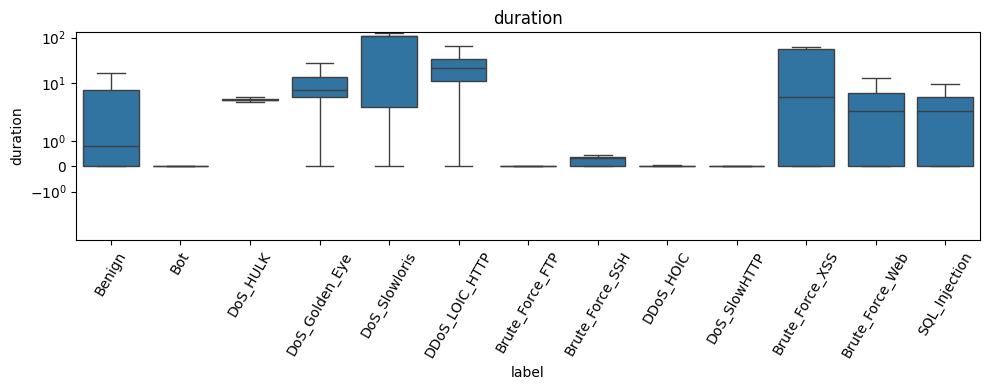

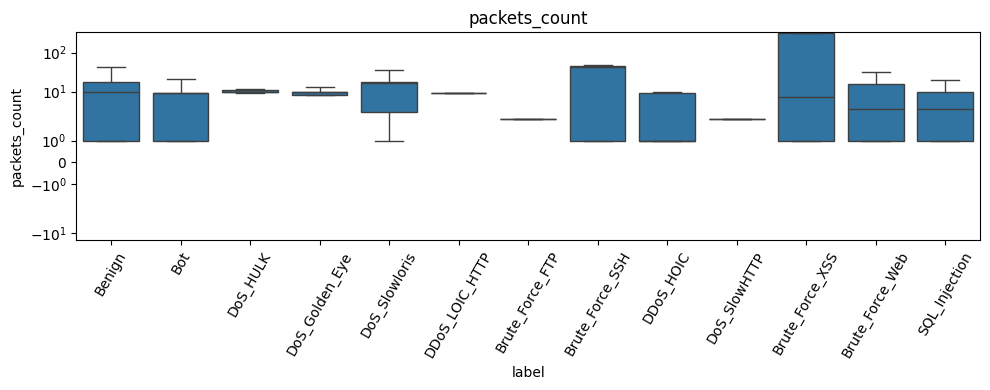

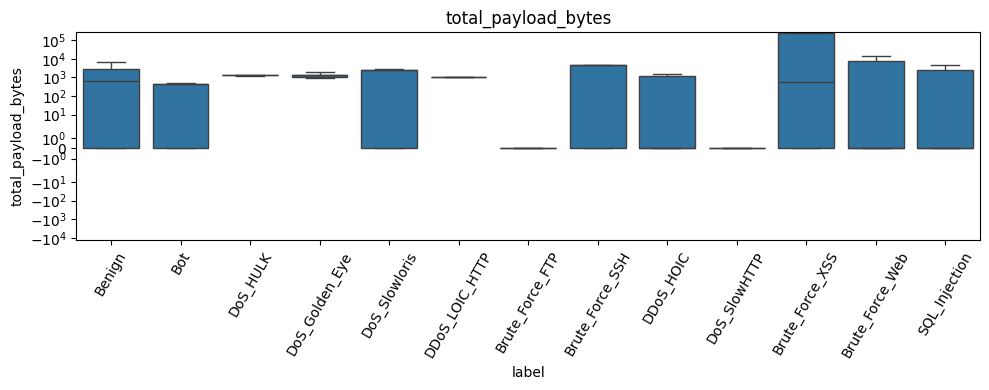

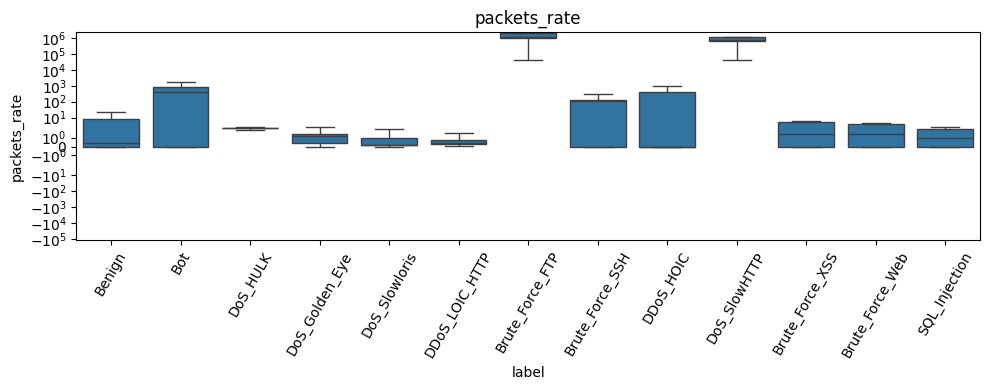

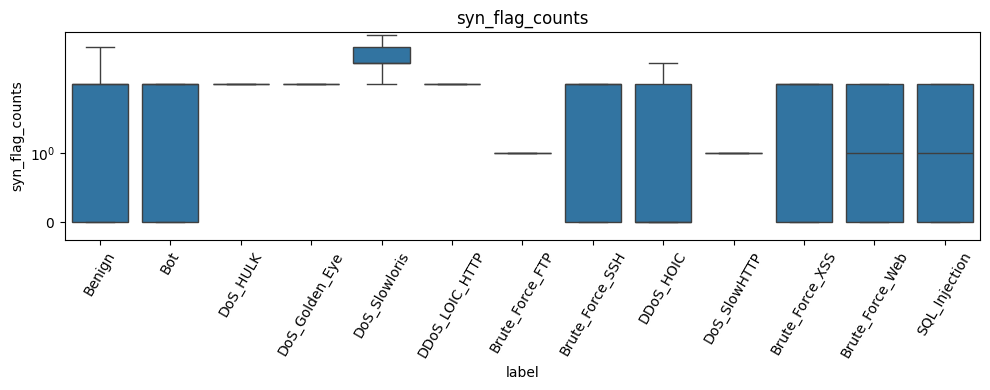

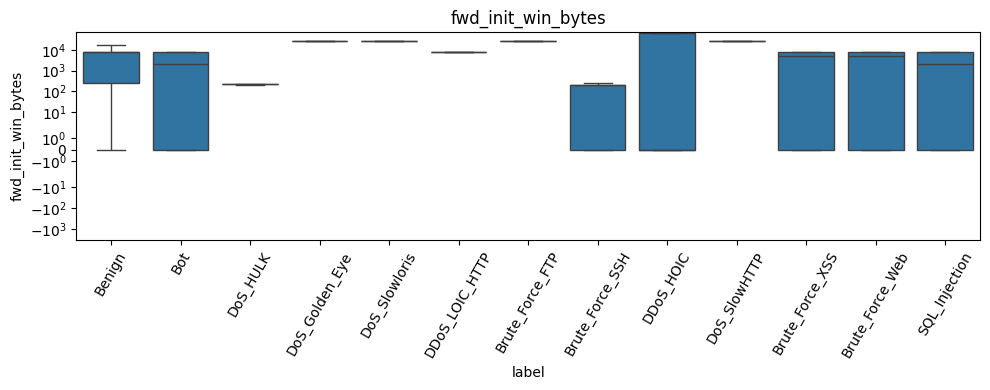

In [10]:
key = ["duration", "packets_count", "total_payload_bytes",
       "packets_rate", "syn_flag_counts", "fwd_init_win_bytes"]

stats = df.groupBy("label").agg(
    *[F.percentile_approx(c, 0.5).alias(f"{c}_median") for c in key])
stats.toPandas().to_csv(f"{BASE}/reports/key_feature_medians.csv", index=False)
stats.show(truncate=False)

counts = dict(zip(lc.label, lc["count"]))
frac = {k: min(1.0, 2000 / v) for k, v in counts.items()}
smp = df.select("label", *key).sampleBy("label", frac, seed=42).toPandas()

import seaborn as sns
for c in key:
    plt.figure(figsize=(10, 4))
    sns.boxplot(data=smp, x="label", y=c, showfliers=False)
    plt.yscale("symlog"); plt.xticks(rotation=60); plt.title(c)
    plt.tight_layout(); plt.savefig(f"{BASE}/reports/box_{c}.png", dpi=120); plt.show()

In [11]:
!ls -lh "{BASE}/reports"

total 428K
-rw------- 1 root root  24K Nov 27 17:41 benign_vs_attack.png
-rw------- 1 root root  53K Nov 27 17:51 box_duration.png
-rw------- 1 root root  59K Nov 27 17:51 box_fwd_init_win_bytes.png
-rw------- 1 root root  56K Nov 27 17:51 box_packets_count.png
-rw------- 1 root root  61K Nov 27 17:51 box_packets_rate.png
-rw------- 1 root root  53K Nov 27 17:51 box_syn_flag_counts.png
-rw------- 1 root root  62K Nov 27 17:51 box_total_payload_bytes.png
-rw------- 1 root root  58K Nov 27 17:41 class_distribution.png
-rw------- 1 root root  421 Nov 27 17:43 handshake_by_label.csv
-rw------- 1 root root  950 Nov 27 17:47 key_feature_medians.csv
-rw------- 1 root root  275 Nov 27 15:27 label_counts.csv
-rw------- 1 root root 2.0K Nov 27 17:41 quality_report.csv


In [12]:
smp.to_csv(f"{BASE}/reports/eda_sample.csv", index=False)